# XGBoost Model – Seoul Bike Sharing Demand

## 1. Project Overview
Predict hourly bike rental demand using XGBoost Regression.

## 2. Dataset
Use the finalized processed dataset and train/test split provided by the team.

## 3. Model Development
- Load the finalized dataset
- Prepare features and target
- Train the XGBoost regressor
- Tune model hyperparameters

## 4. Model Evaluation
- RMSE
- MAE
- R²
- Actual vs. predicted plot

## 5. Model Interpretation
- Feature importance
- Identify the strongest predictors

## 6. Model Comparison
Compare XGBoost results with the team's other models.

## 7. Conclusion
Summarize performance and findings.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All packages imported successfully!")
print("XGBoost version:", xgb.__version__)

All packages imported successfully!
XGBoost version: 3.4.2


In [5]:
import sys
sys.path.append("../")

from my_modules.data_loader import load_seoul_bike_data

df = load_seoul_bike_data("../data/SeoulBikeData.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

df.head()

Dataset shape: (8760, 14)

Column names:
['date', 'rented_bike_count', 'hour', 'temperature_c', 'humidity', 'wind_speed', 'visibility', 'dew_point_temperature_c', 'solar_radiation', 'rainfall', 'snowfall', 'season', 'holiday', 'functioning_day']

Date range:
2017-12-01 00:00:00 to 2018-11-30 00:00:00


,date,rented_bike_count,hour,temperature_c,humidity,wind_speed,visibility,dew_point_temperature_c,solar_radiation,rainfall,snowfall,season,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [6]:
# Check dataset quality

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nFunctioning day counts:")
print(df["functioning_day"].value_counts())

print("\nRental demand statistics:")
print(df["rented_bike_count"].describe())

Missing values:
date                       0
rented_bike_count          0
hour                       0
temperature_c              0
humidity                   0
wind_speed                 0
visibility                 0
dew_point_temperature_c    0
solar_radiation            0
rainfall                   0
snowfall                   0
season                     0
holiday                    0
functioning_day            0
dtype: int64

Duplicate rows:
0

Data types:
date                       datetime64[us]
rented_bike_count                   int64
hour                                int64
temperature_c                     float64
humidity                            int64
wind_speed                        float64
visibility                          int64
dew_point_temperature_c           float64
solar_radiation                   float64
rainfall                          float64
snowfall                          float64
season                                str
holiday                      

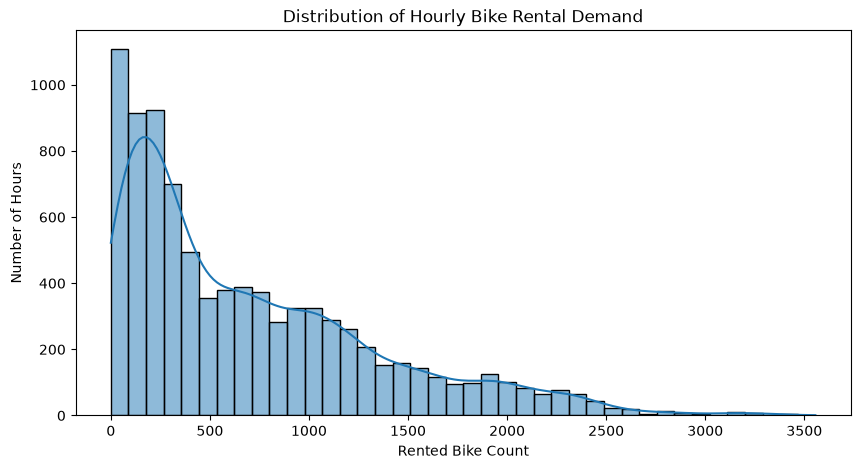

In [7]:
# Visualize rental demand distribution

plt.figure(figsize=(10, 5))
sns.histplot(df["rented_bike_count"], bins=40, kde=True)
plt.title("Distribution of Hourly Bike Rental Demand")
plt.xlabel("Rented Bike Count")
plt.ylabel("Number of Hours")
plt.show()


In [8]:
# Compare rental demand on functioning and non-functioning days

df.groupby("functioning_day")["rented_bike_count"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
functioning_day,,,,,
No,295,0.000000,0.0,0,0
Yes,8465,729.156999,542.0,2,3556


In [9]:
# Create a modeling dataset using functioning days only

model_df = df[df["functioning_day"] == "Yes"].copy()

print("Original dataset:", df.shape)
print("Modeling dataset:", model_df.shape)

print("\nFunctioning day values:")
print(model_df["functioning_day"].value_counts())

print("\nRental demand statistics:")
print(model_df["rented_bike_count"].describe())

Original dataset: (8760, 14)
Modeling dataset: (8465, 14)

Functioning day values:
functioning_day
Yes    8465
Name: count, dtype: int64

Rental demand statistics:
count    8465.000000
mean      729.156999
std       642.351166
min         2.000000
25%       214.000000
50%       542.000000
75%      1084.000000
max      3556.000000
Name: rented_bike_count, dtype: float64


In [10]:
# Inspect categorical feature values

categorical_columns = ["season", "holiday", "functioning_day"]

for column in categorical_columns:
    print(f"\n{column}:")
    print(model_df[column].value_counts())


season:
season
Summer    2208
Winter    2160
Spring    2160
Autumn    1937
Name: count, dtype: int64

holiday:
holiday
No Holiday    8057
Holiday        408
Name: count, dtype: int64

functioning_day:
functioning_day
Yes    8465
Name: count, dtype: int64


In [11]:
# Check chronological order

model_df = model_df.sort_values(["date", "hour"]).reset_index(drop=True)

print("First observation:")
print(model_df[["date", "hour", "rented_bike_count"]].head())

print("\nLast observation:")
print(model_df[["date", "hour", "rented_bike_count"]].tail())

First observation:
        date  hour  rented_bike_count
0 2017-12-01     0                254
1 2017-12-01     1                204
2 2017-12-01     2                173
3 2017-12-01     3                107
4 2017-12-01     4                 78

Last observation:
           date  hour  rented_bike_count
8460 2018-11-30    19               1003
8461 2018-11-30    20                764
8462 2018-11-30    21                694
8463 2018-11-30    22                712
8464 2018-11-30    23                584


In [14]:
# Prepare features for XGBoost

# Create a copy so the original modeling dataset stays unchanged
prepared_df = model_df.copy()

# Extract date-related features
prepared_df["year"] = prepared_df["date"].dt.year
prepared_df["month"] = prepared_df["date"].dt.month
prepared_df["day"] = prepared_df["date"].dt.day
prepared_df["day_of_week"] = prepared_df["date"].dt.day_of_week

# Remove columns that should not be model features
prepared_df = prepared_df.drop(
    columns=["date", "functioning_day"]
)

# Encode categorical variables
prepared_df = pd.get_dummies(
    prepared_df,
    columns=["season", "holiday"],
    dtype=int
)

# Separate features and target
X = prepared_df.drop(columns=["rented_bike_count"])
y = prepared_df["rented_bike_count"]

# Chronological 80/20 train-test split
split_index = int(len(prepared_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining date range:")
print(
    model_df["date"].iloc[0],
    "to",
    model_df["date"].iloc[split_index - 1]
)

print("\nTesting date range:")
print(
    model_df["date"].iloc[split_index],
    "to",
    model_df["date"].iloc[-1]
)

print("\nFeature columns:")
print(X.columns.tolist())

Training features: (6772, 19)
Testing features: (1693, 19)

Training date range:
2017-12-01 00:00:00 to 2018-09-11 00:00:00

Testing date range:
2018-09-11 00:00:00 to 2018-11-30 00:00:00

Feature columns:
['hour', 'temperature_c', 'humidity', 'wind_speed', 'visibility', 'dew_point_temperature_c', 'solar_radiation', 'rainfall', 'snowfall', 'year', 'month', 'day', 'day_of_week', 'season_Autumn', 'season_Spring', 'season_Summer', 'season_Winter', 'holiday_Holiday', 'holiday_No Holiday']


In [15]:
# Train initial XGBoost regression model

xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    objective="reg:squarederror"
)

# Train the model
xgb_model.fit(X_train, y_train)

# Generate predictions
y_pred = xgb_model.predict(X_test)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [16]:
# Evaluate XGBoost model performance

# Calculate evaluation metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display results
print("XGBoost Model Performance")
print("-------------------------")
print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print(f"R²:   {r2:.4f}")

XGBoost Model Performance
-------------------------
RMSE: 287.93
MAE:  211.21
R²:   0.7692


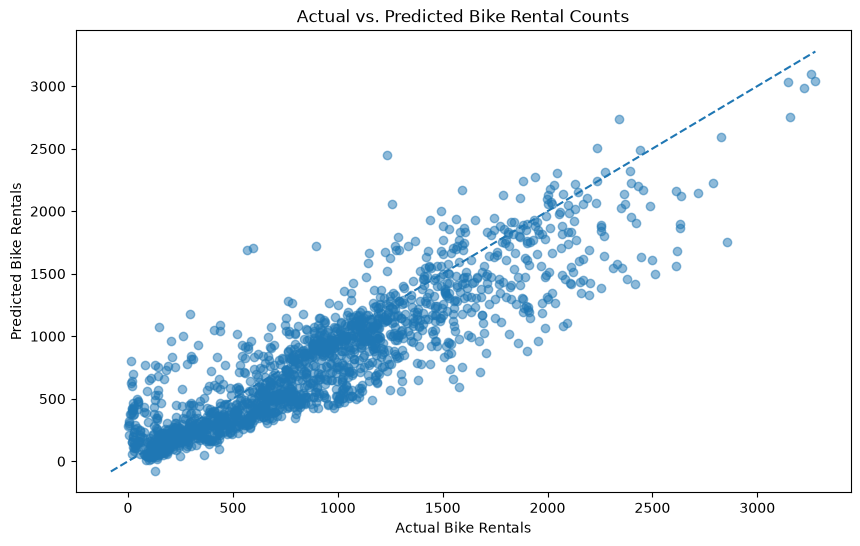

In [17]:
# Actual vs. Predicted Bike Rentals

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Add reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs. Predicted Bike Rental Counts")
plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.show()

XGBoost Feature Importance:
                Feature  Importance
          temperature_c    0.238246
               rainfall    0.196752
                   hour    0.154695
        solar_radiation    0.087206
               humidity    0.065265
            day_of_week    0.046975
          season_Spring    0.046524
                  month    0.044175
        holiday_Holiday    0.036467
dew_point_temperature_c    0.023819
          season_Summer    0.011704
                    day    0.008783
          season_Winter    0.008279
                   year    0.007783
          season_Autumn    0.006910
             visibility    0.006072
               snowfall    0.005944
             wind_speed    0.004402
     holiday_No Holiday    0.000000


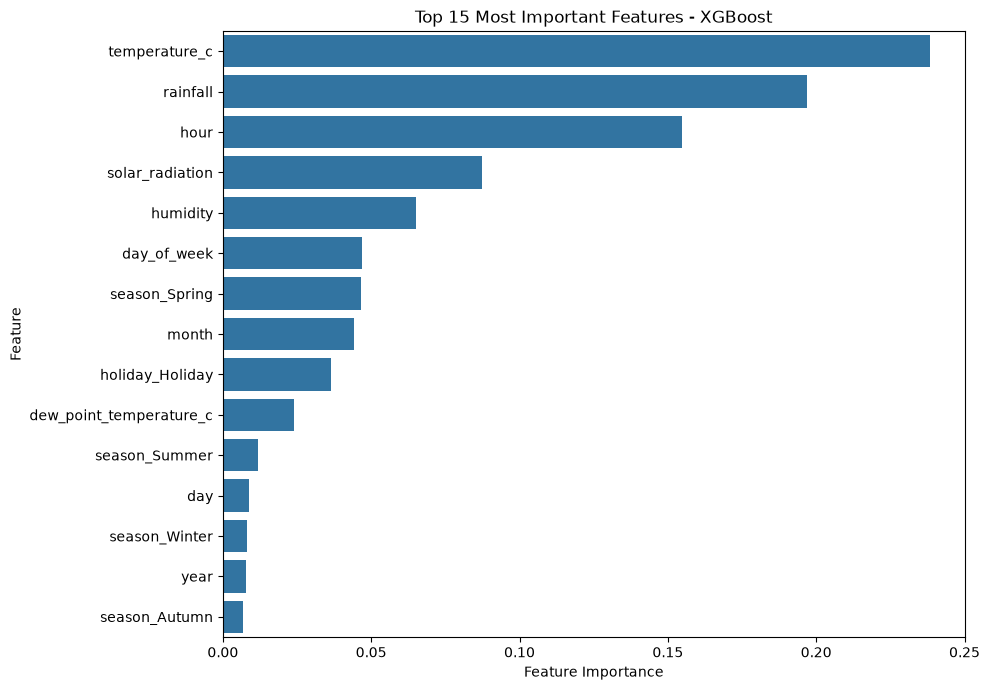

In [18]:
# Analyze XGBoost Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print("XGBoost Feature Importance:")
print(feature_importance.to_string(index=False))

# Visualize the top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Most Important Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [19]:
# XGBoost Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV

# Define hyperparameter options
param_grid = {
    "n_estimators": [300, 500, 700, 1000],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

# Create model
xgb_tuning = xgb.XGBRegressor(
    random_state=42,
    objective="reg:squarederror"
)

# Search for the best parameters
random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Run tuning
random_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'subsample': 1.0, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.9}

Best Cross-Validation RMSE:
318.5604654947917


In [20]:
# Evaluate the tuned XGBoost model

# Get the best model from hyperparameter tuning
best_xgb_model = random_search.best_estimator_

# Generate predictions on the test dataset
y_pred_tuned = best_xgb_model.predict(X_test)

# Calculate evaluation metrics
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_r2 = r2_score(y_test, y_pred_tuned)

# Compare baseline and tuned models
comparison = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R²"],
    "Baseline XGBoost": [rmse, mae, r2],
    "Tuned XGBoost": [tuned_rmse, tuned_mae, tuned_r2]
})

print("Model Performance Comparison:")
print(comparison.to_string(index=False))

print("\nTuned Model Performance:")
print(f"RMSE: {tuned_rmse:.2f}")
print(f"MAE:  {tuned_mae:.2f}")
print(f"R²:   {tuned_r2:.4f}")

Model Performance Comparison:
Metric  Baseline XGBoost  Tuned XGBoost
  RMSE        287.926260     296.071228
   MAE        211.206406     204.049408
    R²          0.769201       0.755959

Tuned Model Performance:
RMSE: 296.07
MAE:  204.05
R²:   0.7560


In [21]:
# Time-Series-Aware XGBoost Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Define chronological cross-validation
time_cv = TimeSeriesSplit(n_splits=3)

# Define hyperparameter options
param_grid = {
    "n_estimators": [300, 500, 700, 1000],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

# Create XGBoost model
xgb_time_tuning = xgb.XGBRegressor(
    random_state=42,
    objective="reg:squarederror"
)

# Set up randomized search
time_search = RandomizedSearchCV(
    estimator=xgb_time_tuning,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=time_cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Run time-series tuning
time_search.fit(X_train, y_train)

# Display results
print("Best Time-Series Parameters:")
print(time_search.best_params_)

print("\nBest Time-Series Cross-Validation RMSE:")
print(-time_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Time-Series Parameters:
{'subsample': 1.0, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.9}

Best Time-Series Cross-Validation RMSE:
410.8759765625


In [22]:
# Evaluate Time-Series Tuned XGBoost Model

# Get the best model from time-series tuning
best_time_model = time_search.best_estimator_

# Generate predictions
y_pred_time = best_time_model.predict(X_test)

# Calculate evaluation metrics
time_rmse = np.sqrt(mean_squared_error(y_test, y_pred_time))
time_mae = mean_absolute_error(y_test, y_pred_time)
time_r2 = r2_score(y_test, y_pred_time)

# Compare all three models
final_comparison = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R²"],
    "Baseline XGBoost": [rmse, mae, r2],
    "Random Search XGBoost": [
        tuned_rmse, tuned_mae, tuned_r2
    ],
    "Time-Series Tuned XGBoost": [
        time_rmse, time_mae, time_r2
    ]
})

print("FINAL MODEL COMPARISON")
print("----------------------")
print(final_comparison.to_string(index=False))

print("\nTime-Series Tuned Model:")
print(f"RMSE: {time_rmse:.2f}")
print(f"MAE:  {time_mae:.2f}")
print(f"R²:   {time_r2:.4f}")

FINAL MODEL COMPARISON
----------------------
Metric  Baseline XGBoost  Random Search XGBoost  Time-Series Tuned XGBoost
  RMSE        287.926260             296.071228                 290.354040
   MAE        211.206406             204.049408                 203.973007
    R²          0.769201               0.755959                   0.765293

Time-Series Tuned Model:
RMSE: 290.35
MAE:  203.97
R²:   0.7653


### XGBoost Model Evaluation and Comparison

Three XGBoost regression models were evaluated using the same chronological test dataset.

The baseline model achieved an RMSE of 287.93, MAE of 211.21, and R² of 0.7692. The randomized hyperparameter search model achieved an RMSE of 296.07, MAE of 204.05, and R² of 0.7560. The time-series tuned model achieved an RMSE of 290.35, MAE of 203.97, and R² of 0.7653.

The baseline model achieved the lowest RMSE and highest R², while the time-series tuned model achieved the lowest MAE. Overall, the baseline model demonstrated the strongest performance based on RMSE and R².

These results show that hyperparameter tuning did not consistently improve model performance. The baseline model will be retained as the leading candidate for further evaluation.

In [24]:
# Residual Analysis - Baseline XGBoost Model

# Calculate residuals (actual minus predicted)
residuals = y_test - y_pred

# Create a results DataFrame
residual_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Residual": residuals
})

# Display residual statistics
print("Residual Statistics")
print("-------------------")
print(residual_df["Residual"].describe())

print("\nLargest Prediction Errors:")
print(
    residual_df.assign(
        Absolute_Error=residual_df["Residual"].abs()
    )
    .nlargest(10, "Absolute_Error")
    .to_string(index=False)
)

Residual Statistics
-------------------
count    1693.000000
mean      110.783173
std       265.838981
min     -1212.339844
25%       -15.994995
50%        91.873047
75%       244.679794
max      1102.851196
Name: Residual, dtype: float64

Largest Prediction Errors:
 Actual   Predicted     Residual  Absolute_Error
   1237 2449.339844 -1212.339844     1212.339844
    567 1688.406006 -1121.406006     1121.406006
    598 1706.163086 -1108.163086     1108.163086
   2857 1754.148804  1102.851196     1102.851196
   2612 1561.390869  1050.609131     1050.609131
   1904  880.069031  1023.930969     1023.930969
   2514 1499.024658  1014.975342     1014.975342
   2074 1079.857056   994.142944      994.142944
   2415 1421.199829   993.800171      993.800171
   1956  963.073120   992.926880      992.926880


In [25]:
# Analyze prediction errors by hour

# Match test predictions with their original dates and hours
error_by_hour = pd.DataFrame({
    "Hour": model_df.iloc[split_index:]["hour"].values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

# Calculate average prediction error for each hour
error_by_hour["Residual"] = (
    error_by_hour["Actual"] - error_by_hour["Predicted"]
)

hourly_errors = error_by_hour.groupby("Hour").agg(
    Average_Actual=("Actual", "mean"),
    Average_Predicted=("Predicted", "mean"),
    Average_Residual=("Residual", "mean"),
    MAE=("Residual", lambda x: x.abs().mean())
)

print("Prediction Error by Hour")
print("-------------------------")
print(hourly_errors.round(2).to_string())

Prediction Error by Hour
-------------------------
      Average_Actual  Average_Predicted  Average_Residual     MAE
Hour                                                             
0             675.14         583.849976             91.29  154.20
1             528.46         426.040009            102.43  151.62
2             359.81         300.660004             59.16  112.11
3             244.13         197.000000             47.13   78.65
4             160.47         128.830002             31.65   60.50
5             154.14         133.990005             20.15   52.10
6             337.74         327.359985             10.38   90.77
7             757.93         612.640015            145.29  337.80
8            1314.51        1068.010010            246.50  453.76
9             828.39         676.280029            152.11  264.57
10            697.94         642.119995             55.83  156.37
11            784.58         749.890015             34.69  154.21
12            914.97     

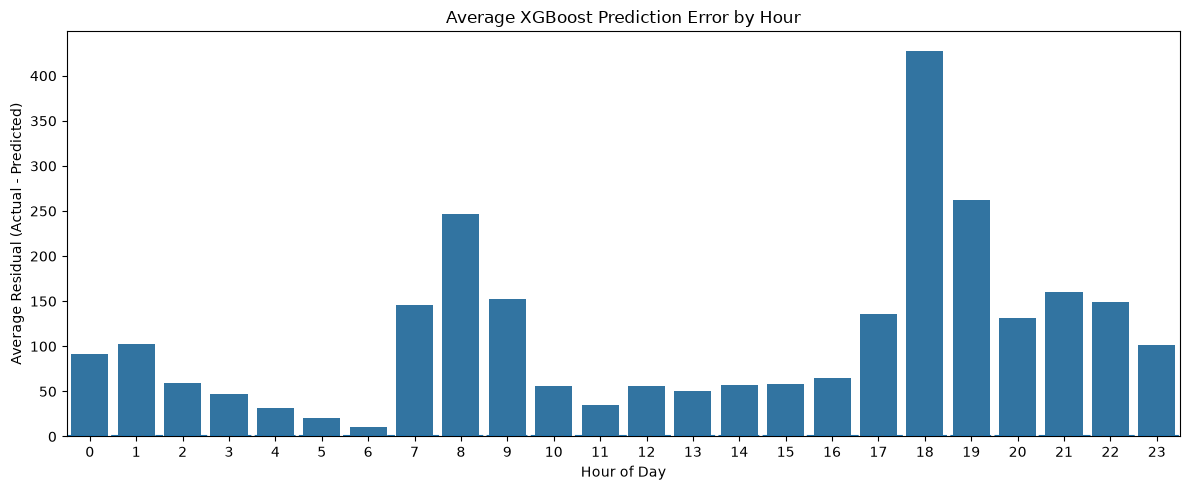

In [26]:
# Visualize average prediction error by hour

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_errors.index,
    y=hourly_errors["Average_Residual"]
)

plt.axhline(0, linestyle="--")

plt.title("Average XGBoost Prediction Error by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

### Residual Analysis by Hour

The residual analysis showed that the baseline XGBoost model generally underpredicts hourly bike rental demand. The largest average underprediction occurred at 6 PM, followed by 7 PM. Noticeable underprediction was also observed during the morning hours, particularly 8 AM and 9 AM.

These findings suggest that the model has difficulty capturing peak commuting demand. Although the model achieved an R² score of 0.7692, its prediction errors vary throughout the day.


In [28]:
# Save the baseline XGBoost model

xgb_model.save_model("xgboost_baseline_model.json")

print("Baseline XGBoost model saved successfully!")

Baseline XGBoost model saved successfully!


In [29]:
# Verify saved XGBoost model

import os

model_path = "xgboost_baseline_model.json"

print("Current working directory:")
print(os.getcwd())

print("\nModel file exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model file size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
    print("Full model path:", os.path.abspath(model_path))

Current working directory:
/Users/alexialucas/Documents/SchoolProjects/CAP_3764_2026_Fall_Team_5/notebooks

Model file exists: True
Model file size: 2825.01 KB
Full model path: /Users/alexialucas/Documents/SchoolProjects/CAP_3764_2026_Fall_Team_5/notebooks/xgboost_baseline_model.json


In [30]:
# Organize and verify the saved XGBoost model

import os
import shutil
import xgboost as xgb
import numpy as np

# Create a models folder in the project directory
os.makedirs("../models", exist_ok=True)

# Move the saved model into the models folder
source_path = "xgboost_baseline_model.json"
destination_path = "../models/xgboost_baseline_model.json"

if os.path.exists(source_path):
    shutil.move(source_path, destination_path)

# Load the saved model
loaded_model = xgb.XGBRegressor()
loaded_model.load_model(destination_path)

# Generate predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Verify predictions match the original model
predictions_match = np.allclose(y_pred, loaded_predictions)

print("Model organization and verification")
print("-----------------------------------")
print("Model file exists:", os.path.exists(destination_path))
print("Model successfully loaded:", loaded_model is not None)
print("Predictions match original model:", predictions_match)
print("Model location:", os.path.abspath(destination_path))


Model organization and verification
-----------------------------------
Model file exists: True
Model successfully loaded: True
Predictions match original model: True
Model location: /Users/alexialucas/Documents/SchoolProjects/CAP_3764_2026_Fall_Team_5/models/xgboost_baseline_model.json


In [32]:
# Check Git repository status

import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    cwd="..",
    capture_output=True,
    text=True
)

print("Git Status:")
print("--------------------")

if result.stdout.strip():
    print(result.stdout)
else:
    print("No uncommitted changes found.")

print("\nCurrent branch:")
branch = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd="..",
    capture_output=True,
    text=True
)

print(branch.stdout.strip())

Git Status:
--------------------
 M notebooks/02_modeling.ipynb
?? 02_modeling.ipynb
?? models/


Current branch:
main


In [33]:
# Inspect project files before committing

import os

print("Root-level notebook:")
root_notebook = "../02_modeling.ipynb"

if os.path.exists(root_notebook):
    print("Exists")
    print("Size:", os.path.getsize(root_notebook), "bytes")
else:
    print("Not found")

print("\nNotebook folder:")
print(os.listdir("."))

print("\nModels folder:")
print(os.listdir("../models"))

Root-level notebook:
Exists
Size: 628 bytes

Notebook folder:
['02_modeling.ipynb', '01_eda.ipynb', '.ipynb_checkpoints']

Models folder:
['xgboost_baseline_model.json']


In [34]:
import json
import os

notebooks = {
    "Main project notebook": "./02_modeling.ipynb",
    "Extra root notebook": "../02_modeling.ipynb"
}

for name, path in notebooks.items():
    with open(path, "r", encoding="utf-8") as file:
        notebook = json.load(file)

    cells = notebook.get("cells", [])

    print(f"\n{name}")
    print("File size:", os.path.getsize(path), "bytes")
    print("Number of cells:", len(cells))

    for cell in cells[:5]:
        content = "".join(cell.get("source", []))
        print("-", cell["cell_type"], ":", content[:100].replace("\n", " "))


Main project notebook
File size: 300911 bytes
Number of cells: 27
- markdown : # XGBoost Model – Seoul Bike Sharing Demand  ## 1. Project Overview Predict hourly bike rental deman
- code : import pandas as pd import numpy as np import matplotlib.pyplot as plt import seaborn as sns import 
- code : import sys sys.path.append("../")  from my_modules.data_loader import load_seoul_bike_data  df = loa
- code : # Check dataset quality  print("Missing values:") print(df.isnull().sum())  print("\nDuplicate rows:
- code : # Visualize rental demand distribution  plt.figure(figsize=(10, 5)) sns.histplot(df["rented_bike_cou

Extra root notebook
File size: 628 bytes
Number of cells: 1
- code : 


In [35]:
# Remove the accidental empty notebook from the project root

import os

extra_notebook = "../02_modeling.ipynb"

if os.path.exists(extra_notebook):
    os.remove(extra_notebook)
    print("Extra empty notebook removed successfully!")
else:
    print("Extra notebook was not found.")

Extra empty notebook removed successfully!


In [36]:
result = subprocess.run(
    ["git", "status", "--short"],
    cwd="..",
    capture_output=True,
    text=True
)

print(result.stdout)

 M notebooks/02_modeling.ipynb
?? models/



In [37]:
# Review files before committing

import os

files_to_check = [
    "notebooks/02_modeling.ipynb",
    "models/xgboost_baseline_model.json"
]

for file_path in files_to_check:
    full_path = os.path.join("..", file_path)

    print(f"\nFile: {file_path}")
    print("Exists:", os.path.exists(full_path))

    if os.path.exists(full_path):
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"Size: {size_mb:.2f} MB")


File: notebooks/02_modeling.ipynb
Exists: True
Size: 0.29 MB

File: models/xgboost_baseline_model.json
Exists: True
Size: 2.76 MB


In [38]:
# Stage only the XGBoost notebook and saved model

import subprocess

subprocess.run(
    [
        "git", "add",
        "notebooks/02_modeling.ipynb",
        "models/xgboost_baseline_model.json"
    ],
    cwd="..",
    check=True
)

print("Your two XGBoost files have been staged!")

Your two XGBoost files have been staged!


In [39]:
result = subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    cwd="..",
    capture_output=True,
    text=True
)

print(result.stdout)

 models/xgboost_baseline_model.json |    1 +
 notebooks/02_modeling.ipynb        | 1681 ++++++++++++++++++++++++++++++++++++
 2 files changed, 1682 insertions(+)



In [40]:
# Commit XGBoost implementation

subprocess.run(
    [
        "git", "commit",
        "-m",
        "Add XGBoost model implementation and evaluation"
    ],
    cwd="..",
    check=True
)

print("XGBoost implementation committed successfully!")

[main ab60229] Add XGBoost model implementation and evaluation
 Committer: Alexia Lucas <alexialucas@Alexias-MacBook-Air-3.local>
Your name and email address were configured automatically based
on your username and hostname. Please check that they are accurate.
You can suppress this message by setting them explicitly. Run the
following command and follow the instructions in your editor to edit
your configuration file:

    git config --global --edit

After doing this, you may fix the identity used for this commit with:

    git commit --amend --reset-author

 2 files changed, 1682 insertions(+)
 create mode 100644 models/xgboost_baseline_model.json
XGBoost implementation committed successfully!


In [41]:
# Check Git identity

for setting in ["user.name", "user.email"]:
    result = subprocess.run(
        ["git", "config", "--global", setting],
        capture_output=True,
        text=True
    )
    print(f"{setting}: {result.stdout.strip()}")

user.name: 
user.email: 


In [42]:
# Configure GitHub identity
import subprocess

subprocess.run(
    ["git", "config", "--global", "user.name", "alexialucas"],
    check=True
)

subprocess.run(
    ["git", "config", "--global", "user.email", "alexialucasspam@gmail.com"],
    check=True
)

# Update the existing commit author
subprocess.run(
    ["git", "commit", "--amend", "--reset-author", "--no-edit"],
    cwd="..",
    check=True
)

# Verify updated commit
result = subprocess.run(
    ["git", "log", "-1", "--format=fuller"],
    cwd="..",
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)

[main ed77d56] Add XGBoost model implementation and evaluation
 2 files changed, 1682 insertions(+)
 create mode 100644 models/xgboost_baseline_model.json
commit ed77d564842256d8117d48424e66c46709ae98f2
Author:     alexialucas <alexialucasspam@gmail.com>
AuthorDate: Fri Nov 13 17:02:01 2026 -0500
Commit:     alexialucas <alexialucasspam@gmail.com>
CommitDate: Fri Nov 13 17:02:01 2026 -0500

    Add XGBoost model implementation and evaluation



In [43]:
# Check branch and remote status

commands = [
    ["git", "status"],
    ["git", "branch", "-vv"],
    ["git", "remote", "-v"],
    ["git", "log", "-1", "--oneline"]
]

for command in commands:
    result = subprocess.run(
        command,
        cwd="..",
        capture_output=True,
        text=True
    )
    print("\n$", " ".join(command))
    print(result.stdout)


$ git status
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebooks/02_modeling.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


$ git branch -vv
* main ed77d56 [origin/main: ahead 1] Add XGBoost model implementation and evaluation


$ git remote -v
origin	https://github.com/NikosKarakasis/CAP_3764_2026_Fall_Team_5.git (fetch)
origin	https://github.com/NikosKarakasis/CAP_3764_2026_Fall_Team_5.git (push)


$ git log -1 --oneline
ed77d56 Add XGBoost model implementation and evaluation



In [44]:
# Refresh GitHub information without changing your files

import subprocess

commands = [
    ["git", "fetch", "origin"],
    ["git", "status", "-sb"],
    ["git", "log", "--oneline", "--decorate", "--graph", "-8", "--all"],
    ["git", "diff", "--stat"],
    ["git", "show", "-s", "--format=Commit parent: %P", "HEAD"]
]

for command in commands:
    result = subprocess.run(
        command,
        cwd="..",
        capture_output=True,
        text=True
    )

    print("\n$", " ".join(command))
    print(result.stdout)

    if result.returncode != 0:
        print("Error:", result.stderr)


$ git fetch origin


$ git status -sb
## main...origin/main [ahead 1]
 M notebooks/02_modeling.ipynb


$ git log --oneline --decorate --graph -8 --all
* ed77d56 (HEAD -> main) Add XGBoost model implementation and evaluation
*   27c3351 (origin/main, origin/HEAD) Merge pull request #18 from NikosKarakasis/First-Submission-Feedback-Update
|\  
| * 5686939 (origin/First-Submission-Feedback-Update) Forgor to change the name of the .yml inside of the .yml file.
| * a5dc5f7 Another README Update
| * 2a740a2 Updated README
| * 266770f Updated .yml name again because I'm worried the parenthesis would cause issues.
| * 7c3b501 I updated the submission based on the feedback the professor gave us.
|/  
* 4676687 (origin/Copy-Of-Main) Revise README for Seoul Bike Sharing Demand project


$ git diff --stat
 notebooks/02_modeling.ipynb | 192 +++++++++++++++++++++++++++++++++++++++++++-
 1 file changed, 191 insertions(+), 1 deletion(-)


$ git show -s --format=Commit parent: %P HEAD
Commit parent: 2

In [45]:
# Inspect additional notebook changes

result = subprocess.run(
    ["git", "diff", "--", "notebooks/02_modeling.ipynb"],
    cwd="..",
    capture_output=True,
    text=True
)

print(result.stdout[:12000])

diff --git a/notebooks/02_modeling.ipynb b/notebooks/02_modeling.ipynb
index 1ee0f34..f28e1b9 100644
--- a/notebooks/02_modeling.ipynb
+++ b/notebooks/02_modeling.ipynb
@@ -1650,9 +1650,199 @@
   },
   {
    "cell_type": "code",
-   "execution_count": null,
+   "execution_count": 38,
    "id": "f347162b-bfc0-41ed-b85b-d9d2dd97729d",
    "metadata": {},
+   "outputs": [
+    {
+     "name": "stdout",
+     "output_type": "stream",
+     "text": [
+      "Your two XGBoost files have been staged!\n"
+     ]
+    }
+   ],
+   "source": [
+    "# Stage only the XGBoost notebook and saved model\n",
+    "\n",
+    "import subprocess\n",
+    "\n",
+    "subprocess.run(\n",
+    "    [\n",
+    "        \"git\", \"add\",\n",
+    "        \"notebooks/02_modeling.ipynb\",\n",
+    "        \"models/xgboost_baseline_model.json\"\n",
+    "    ],\n",
+    "    cwd=\"..\",\n",
+    "    check=True\n",
+    ")\n",
+    "\n",
+    "print(\"Your two XGBoost files have been staged!\")"
+   ]
+  },
+ 

In [46]:
result = subprocess.run(
    ["git", "status", "--short"],
    cwd="..",
    capture_output=True,
    text=True
)

print(result.stdout)

 M notebooks/02_modeling.ipynb

